# Clasificación multi-etiqueta de géneros de películas
Walkthrough de referencia. La lógica vive en `src/genre_clf.py` (y `src/roberta.py` para el Transformer); aquí solo se explora y se muestran resultados.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import pandas as pd
import genre_clf as g

train, test = g.load_data()
print(train.shape, test.shape)
train.head(3)

(8475, 3) (942, 2)


,movie_name,genre,description
0,Silent Hill,"Horror, Mystery","Rose, a desperate mother takes her adopted dau..."
1,Breaking the Waves,"Drama, Romance","In a small and conservative Scottish village, ..."
2,Wind Chill,"Drama, Horror, Thriller",Two college students share a ride home for the...


## Exploración: frecuencia de géneros y longitud de sinopsis

Palabras por sinopsis (media/mediana): [45.0, 41.0]


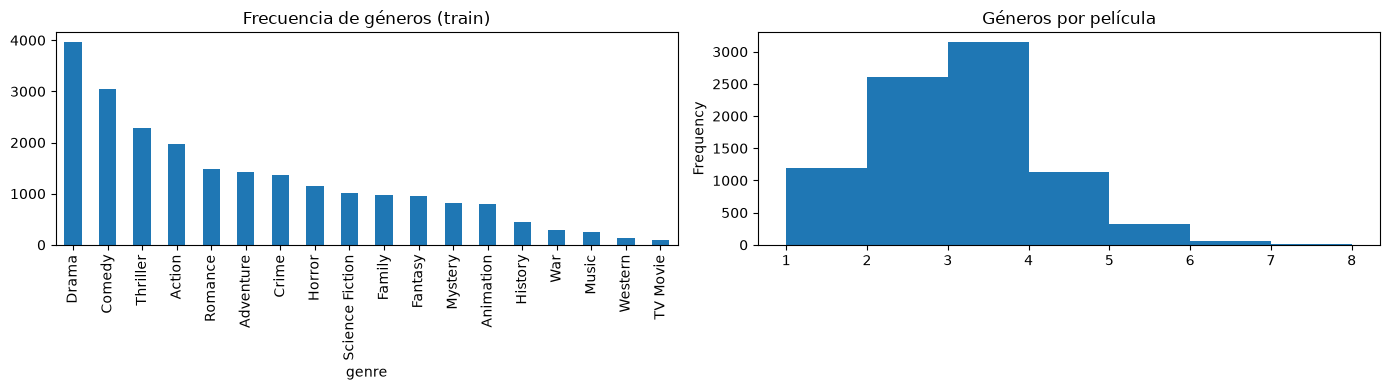

In [2]:
genres = train['genre'].str.split(', ').explode()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
genres.value_counts().plot.bar(ax=ax[0], title='Frecuencia de géneros (train)')
train['genre'].str.count(',').add(1).plot.hist(ax=ax[1], bins=range(1, 9), title='Géneros por película')
plt.tight_layout()
print('Palabras por sinopsis (media/mediana):', train['description'].str.split().str.len().agg(['mean', 'median']).round(0).tolist())

## Modelos clásicos (NB y LR)
Split 60/20/20 con semilla fija: el umbral global se elige en *val* y las métricas se miden en *holdout*.

In [3]:
s, results, _ = g.run(train)
pd.DataFrame(results).T.round(3)

,micro_f1,macro_f1,samples_f1,precision,recall,hamming_loss,threshold
Más frecuente (Drama),0.254,0.035,0.280,0.465,0.175,0.152,NaN
Naive Bayes (BoW),0.591,0.501,0.579,0.550,0.638,0.131,0.250
Regresión logística (TF-IDF),0.580,0.408,0.574,0.504,0.683,0.146,0.225


## Resultados incluyendo RoBERTa
`results/metrics.json` acumula también la ejecución de `python src/roberta.py`.

In [4]:
pd.DataFrame(json.load(open('../results/metrics.json'))).T.round(3)

,micro_f1,macro_f1,samples_f1,precision,recall,hamming_loss,threshold
Más frecuente (Drama),0.254,0.035,0.280,0.465,0.175,0.152,NaN
Naive Bayes (BoW),0.591,0.501,0.579,0.550,0.638,0.131,0.250
Regresión logística (TF-IDF),0.580,0.408,0.574,0.504,0.683,0.146,0.225
"RoBERTa (5085 train, 3 ep)",0.650,0.537,0.644,0.608,0.699,0.111,0.325
